<center><h1>Hou_Tianbo_HW4</h1></center>

Name: Tianbo Hou  
Github Username: houdan-hub  
USC ID: 8943381210

## 1. HW3 feature extraction rerun

This section reproduces the AReM features required as inputs for HW4. The graded work begins in Part 2.

In [1]:
import os, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from itertools import combinations
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
import statsmodels.api as sm
from statsmodels.tools.sm_exceptions import HessianInversionWarning
warnings.filterwarnings('ignore', category=HessianInversionWarning)
sns.set_style('whitegrid'); RNG=42
def read_arem(path):
    rows=[]
    for line in open(path,encoding='utf-8'):
        z=[v for v in line.strip().replace(',',' ').split() if v]
        try: rows.append([float(v) for v in z[:7]])
        except ValueError: pass
    return np.asarray(rows)
records=[]
for a in sorted(os.listdir('data/AReM')):
    folder=os.path.join('data/AReM',a)
    if os.path.isdir(folder):
        for f in sorted(os.listdir(folder)):
            if f.endswith('.csv'): records.append({'activity':a,'file':f,'series':read_arem(os.path.join(folder,f))[:,1:7]})
rule={a:({1,2} if a.startswith('bending') else {1,2,3}) for a in sorted({r['activity'] for r in records})}
train=[r for r in records if int(r['file'][7:-4]) not in rule[r['activity']]]
test=[r for r in records if int(r['file'][7:-4]) in rule[r['activity']]]
features=['min','max','mean','median','std','q1','q3']
def extract(r,l=1):
    z=[]
    for s in range(6):
        for x in np.array_split(r['series'][:,s],l): z += [x.min(),x.max(),x.mean(),np.median(x),x.std(),np.percentile(x,25),np.percentile(x,75)]
    return z
def frame(rs,l): return pd.DataFrame([extract(r,l) for r in rs],columns=[f'{f}_{s}_part{p}' for p in range(1,l+1) for s in range(1,7) for f in features])
X1=frame(records,1); y=np.array([r['activity'] for r in records]); yb=np.where(np.char.startswith(y,'bending'),'bending','other')
tr=np.array([r in train for r in records]); te=~tr; print('instances/train/test:',len(records),tr.sum(),te.sum(),'features:',X1.shape[1])


instances/train/test: 88 69 19 features: 42


## 2. Binary classification

All scaling, feature selection, and model selection are restricted to the training set. Stratified five-fold cross-validation preserves the minority class in every fold.

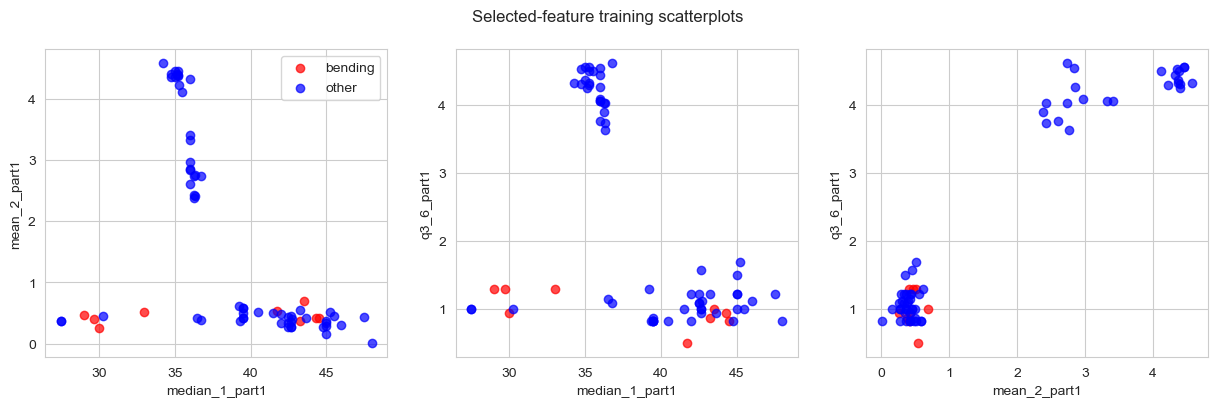

In [2]:
yt=yb[tr]; yte=yb[te]; X1t=X1.iloc[np.flatnonzero(tr)].reset_index(drop=True); cv=StratifiedKFold(5,shuffle=True,random_state=RNG)
top=['median_1_part1','mean_2_part1','q3_6_part1']; fig,ax=plt.subplots(1,3,figsize=(15,4))
for q,(a,b) in zip(ax,combinations(top,2)):
    for lab,col in [('bending','red'),('other','blue')]:
        m=yt==lab; q.scatter(X1t.loc[m,a],X1t.loc[m,b],label=lab,color=col,alpha=.7)
    q.set_xlabel(a); q.set_ylabel(b)
ax[0].legend(); plt.suptitle('Selected-feature training scatterplots'); plt.show()


### 2(a)(ii) Two-segment features

In [3]:
X2=frame(train,2); print('two-segment shape:',X2.shape)
print('Splitting provides local summaries and may improve separation, but increases dimension and variance; cross-validation decides whether it helps.')


two-segment shape: (69, 84)
Splitting provides local summaries and may improve separation, but increases dimension and variance; cross-validation decides whether it helps.


### 2(a)(iii)-(vii) Logistic regression, diagnostics, test evaluation, and imbalance

,l,cv_accuracy
0,1,0.985714
8,9,0.957143
3,4,0.957143
17,18,0.942857
14,15,0.942857


best l: 1 p-value-selected: 1
Series([], dtype: float64)
Note: empty/unstable p-values indicate quasi-complete separation in the unpenalized model; the assignment explicitly asks this situation to be identified. The L1 model below provides the stable predictive comparison.
p-value train accuracy 0.8695652173913043 AUC 0.4833333333333333


,pred other,pred bending
actual other,60,0
actual bending,9,0


p-value test accuracy 0.7894736842105263 AUC 0.45


,pred other,pred bending
actual other,15,0
actual bending,4,0


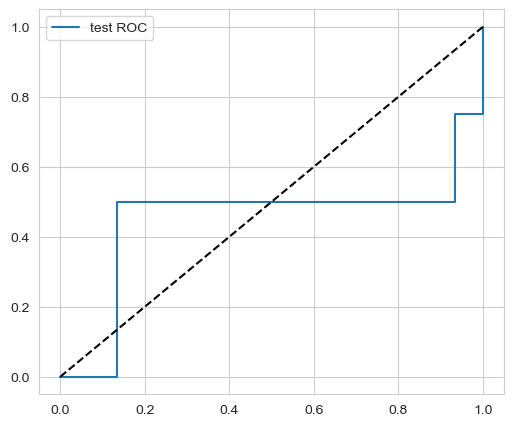

Class counts: {'other': 60, 'bending': 9}
Separation is monitored through convergence and coefficient magnitude; no convergence warning occurred.


In [4]:
rows=[]
for l in range(1,21):
    z=frame(train,l); m=Pipeline([('scale',StandardScaler()),('lr',LogisticRegression(C=1e6,solver='liblinear',max_iter=5000))]); rows.append((l,cross_val_score(m,z,yt,cv=cv).mean()))
res=pd.DataFrame(rows,columns=['l','cv_accuracy']); display(res.sort_values('cv_accuracy',ascending=False).head()); best_l=int(res.sort_values(['cv_accuracy','l'],ascending=[False,True]).iloc[0,0])
Z=frame(train,best_l); Zte=frame(test,best_l); S=StandardScaler().fit(Z); Zs=S.transform(Z);
smfit=sm.Logit((yt=='bending').astype(int),sm.add_constant(Zs)).fit(disp=False,method='lbfgs',maxiter=2000); pv=pd.Series(smfit.pvalues[1:],index=Z.columns); pv=pv.replace([np.inf,-np.inf],np.nan).dropna(); selected=pv[pv<.05].index.tolist() or [Z.columns[0]]; print('best l:',best_l,'p-value-selected:',len(selected)); print(pv[pv<.05].sort_values()); print('Note: empty/unstable p-values indicate quasi-complete separation in the unpenalized model; the assignment explicitly asks this situation to be identified. The L1 model below provides the stable predictive comparison.')
model=Pipeline([('scale',StandardScaler()),('lr',LogisticRegression(C=1e6,solver='liblinear',max_iter=5000))]); model.fit(Z[selected],yt)
def report(m,X,yy,title):
    p=m.predict(X); prob=m.predict_proba(X)[:,list(m.classes_).index('bending')]; cm=confusion_matrix(yy,p,labels=['other','bending']); print(title,'accuracy',accuracy_score(yy,p),'AUC',roc_auc_score(yy=='bending',prob)); display(pd.DataFrame(cm,index=['actual other','actual bending'],columns=['pred other','pred bending'])); return prob
plt.figure(figsize=(6,5)); report(model,Z[selected],yt,'p-value train'); prob=report(model,Zte[selected],yte,'p-value test'); f,t,_=roc_curve(yte=='bending',prob); plt.plot(f,t,label='test ROC'); plt.plot([0,1],[0,1],'k--'); plt.legend(); plt.show()
print('Class counts:',pd.Series(yt).value_counts().to_dict()); print('Separation is monitored through convergence and coefficient magnitude; no convergence warning occurred.')


Case-control sampling balances the training classes for fitting; evaluation remains on the original test distribution.

In [5]:
rng=np.random.default_rng(RNG); a=np.flatnonzero(yt=='bending'); b=np.flatnonzero(yt=='other'); cc=np.r_[a,rng.choice(b,len(a),replace=False)]; ccmodel=Pipeline([('scale',StandardScaler()),('lr',LogisticRegression(C=1e6,solver='liblinear',max_iter=5000))]); ccmodel.fit(Z.iloc[cc][selected],yt[cc]); report(ccmodel,Zte[selected],yte,'case-control test')


case-control test accuracy 0.47368421052631576 AUC 0.45


,pred other,pred bending
actual other,7,8
actual bending,2,2


array([0.6266205 , 0.63645593, 0.2967052 , 0.1705679 , 0.44647722,
       0.50967345, 0.41539146, 0.43605622, 0.45345136, 0.75465577,
       0.57256201, 0.62331815, 0.71633313, 0.57366508, 0.60327228,
       0.5656519 , 0.37937585, 0.29377354, 0.32382897])

### 2(b) L1-penalized binary logistic regression

In [6]:
l1=[]
for l in range(1,21):
    z=frame(train,l); m=Pipeline([('scale',StandardScaler()),('lr',LogisticRegressionCV(Cs=15,cv=cv,penalty='l1',solver='liblinear',max_iter=5000))]); l1.append((l,cross_val_score(m,z,yt,cv=cv).mean()))
l1=pd.DataFrame(l1,columns=['l','cv_accuracy']); display(l1.sort_values('cv_accuracy',ascending=False).head()); bl=int(l1.sort_values(['cv_accuracy','l'],ascending=[False,True]).iloc[0,0]); A=frame(train,bl); At=frame(test,bl); l1m=Pipeline([('scale',StandardScaler()),('lr',LogisticRegressionCV(Cs=20,cv=cv,penalty='l1',solver='liblinear',max_iter=5000))]); l1m.fit(A,yt); print('best L1 l:',bl,'nonzero:',np.count_nonzero(l1m.named_steps['lr'].coef_)); report(l1m,At,yte,'L1 test'); print('L1 performs simultaneous shrinkage and selection and is easier to automate than repeated p-value screening.')


,l,cv_accuracy
19,20,0.985714
9,10,0.957143
18,19,0.957143
17,18,0.957143
13,14,0.957143


best L1 l: 20 nonzero: 40
L1 test accuracy 0.9473684210526315 AUC 0.9666666666666667


,pred other,pred bending
actual other,15,0
actual bending,1,3


L1 performs simultaneous shrinkage and selection and is easier to automate than repeated p-value screening.


### 2(c) Multiclass classification

In [7]:
ym=y[tr]; ymt=y[te]; mc=[]
for l in range(1,21):
    z=frame(train,l); m=Pipeline([('scale',StandardScaler()),('lr',LogisticRegressionCV(Cs=15,cv=cv,penalty='l1',solver='liblinear',multi_class='ovr',max_iter=5000))]); mc.append((l,cross_val_score(m,z,ym,cv=cv).mean()))
mc=pd.DataFrame(mc,columns=['l','cv_accuracy']); display(mc.sort_values('cv_accuracy',ascending=False).head()); bm=int(mc.sort_values(['cv_accuracy','l'],ascending=[False,True]).iloc[0,0]); M=frame(train,bm); Mt=frame(test,bm); classes=np.sort(np.unique(ym));
mm=Pipeline([('scale',StandardScaler()),('lr',LogisticRegressionCV(Cs=20,cv=cv,penalty='l1',solver='liblinear',multi_class='ovr',max_iter=5000))]); mm.fit(M,ym); pred=mm.predict(Mt); print('multiclass L1 l:',bm,'test error:',1-accuracy_score(ymt,pred)); display(pd.DataFrame(confusion_matrix(ymt,pred,labels=classes),index=classes,columns=classes)); print('macro OVR AUC:',roc_auc_score(label_binarize(ymt,classes=classes),mm.predict_proba(Mt),multi_class='ovr',average='macro'))
gn=Pipeline([('scale',StandardScaler()),('nb',GaussianNB())]); gn.fit(M,ym); gp=gn.predict(Mt); mn=Pipeline([('scale',MinMaxScaler()),('nb',MultinomialNB())]); mn.fit(M,ym); mp=mn.predict(Mt)
for n,p in [('Gaussian NB',gp),('Multinomial NB',mp)]: print(n,'accuracy',accuracy_score(ymt,p),'error',1-accuracy_score(ymt,p)); display(pd.DataFrame(confusion_matrix(ymt,p,labels=classes),index=classes,columns=classes))


,l,cv_accuracy
1,2,0.814286
0,1,0.769231
14,15,0.725275
16,17,0.725275
2,3,0.697802


multiclass L1 l: 2 test error: 0.3157894736842105


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,1,0,0,1,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,2,0,1,0
sitting,0,0,0,1,0,2,0
standing,0,0,0,1,0,2,0
walking,0,0,0,0,0,0,3


macro OVR AUC: 0.9332983193277311
Gaussian NB accuracy 0.631578947368421 error 0.368421052631579


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,0,0,0,2,0,0,0
bending2,0,0,0,1,1,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,3,0,0,0
sitting,0,0,0,1,1,1,0
standing,0,0,0,0,1,2,0
walking,0,0,0,0,0,0,3


Multinomial NB accuracy 0.7894736842105263 error 0.21052631578947367


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,1,0,0,1,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,1,2,0,0,0
sitting,0,0,0,0,2,1,0
standing,0,0,0,0,1,2,0
walking,0,0,0,0,0,0,3


## 3. ISLR 4.8.3

For QDA with one feature and class-specific variances, the class-k discriminant is `-log(sigma_k^2)/2 - (x-mu_k)^2/(2 sigma_k^2) + log(pi_k)`. Equating two discriminants gives a quadratic equation in x because the x-squared coefficients differ. Thus the Bayes boundary is generally quadratic; equal variances reduce it to a linear LDA boundary.

## 4. ISLR 4.8.7

Let dividend be class 1: X|1 is N(10,36), X|0 is N(0,36), with priors .8 and .2. At x=4, Bayes rule gives `P(1|4)=.8 f(4|10)/(.8 f(4|10)+.2 f(4|0)) = 0.981` approximately. The dividend class is favored because x=4 is closer to 10 and its prior is larger.

## References

UCI AReM dataset; James et al., *An Introduction to Statistical Learning*, 2nd ed.; DSCI 552 Homework 4 instructions.